# RetailNova — Predicción de abandono de clientes
### Evaluación Parcial N°5 — Implementación técnica

Este notebook implementa el pipeline completo de ciencia de datos definido en el plan de
proyecto (EV3), siguiendo las fases de **CRISP-DM**: comprensión de los datos, preparación,
modelado, evaluación y generación de resultados para el dashboard de negocio.

**Trazabilidad con el WBS (EV3):**
| Fase WBS | Sección de este notebook |
|---|---|
| 2.0 Comprensión de los datos | 1. Carga y exploración (EDA) |
| 3.0 Preparación de datos | 2. Diagnóstico de calidad · 3. Limpieza e imputación · 4. Feature engineering |
| 4.0 Modelado | 5. Entrenamiento y ajuste de umbral |
| 5.0 Evaluación | 6. Evaluación global y por región (RF07) |
| 6.0 Despliegue | 7. Exportación de resultados para el dashboard |


## 1. Carga de datos y exploración inicial (EDA)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 110

df = pd.read_excel('../data/retailnova_clientes.xlsx', sheet_name='Clientes RetailNova',
                    parse_dates=['fecha_registro', 'fecha_ultima_compra'])
print(f"Filas: {len(df):,} | Columnas: {df.shape[1]}")
df.head()

Filas: 185,000 | Columnas: 18


,cliente_id,edad,comuna,region,fecha_registro,canal_compra,cantidad_compras,frecuencia_compra_dias,monto_promedio,monto_total_acumulado,categoria_principal,uso_promociones,devoluciones,reclamos,interacciones_campanas,fecha_ultima_compra,dias_desde_ultima_compra,abandono
0,CUST-000001,53.0,San Antonio,Valparaíso,2026-06-09,Tienda física,2,40.4,54100,101300,Hogar,3,0,0,0,2026-09-25,6,0
1,CUST-000002,31.0,Maipú,Metropolitana,2024-02-25,E-commerce,8,92.1,31300,228000,Hogar,3,0,0,1,2026-02-25,218,1
2,CUST-000003,25.0,Quilpué,Valparaíso,2024-04-30,E-commerce,13,57.4,31200,401100,Hogar,0,0,0,2,2026-06-04,119,1
3,CUST-000004,24.0,Valparaíso,Valparaíso,2025-07-24,Tienda física,2,170.5,58100,122000,Electrodomésticos,1,0,0,3,2025-09-15,381,1
4,CUST-000005,43.0,Ñuñoa,Metropolitana,2024-04-25,Tienda física,20,40.0,12800,248100,Hogar,2,0,0,4,2026-09-19,12,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 185000 entries, 0 to 184999
Data columns (total 18 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   cliente_id                185000 non-null  str           
 1   edad                      170200 non-null  float64       
 2   comuna                    170200 non-null  str           
 3   region                    185000 non-null  str           
 4   fecha_registro            185000 non-null  datetime64[us]
 5   canal_compra              185000 non-null  str           
 6   cantidad_compras          185000 non-null  int64         
 7   frecuencia_compra_dias    185000 non-null  float64       
 8   monto_promedio            185000 non-null  int64         
 9   monto_total_acumulado     185000 non-null  int64         
 10  categoria_principal       185000 non-null  str           
 11  uso_promociones           185000 non-null  int64         
 12  devoluciones 

In [4]:
print("Tasa de abandono global: {:.1%}".format(df['abandono'].mean()))
print()
print("Distribución por región:")
print(df['region'].value_counts(normalize=True).round(3))
print()
print("Distribución por categoría de producto:")
print(df['categoria_principal'].value_counts(normalize=True).round(3))

Tasa de abandono global: 23.9%

Distribución por región:
region
Metropolitana    0.68
Valparaíso       0.19
Biobío           0.13
Name: proportion, dtype: float64

Distribución por categoría de producto:
categoria_principal
Hogar                0.459
Tecnología           0.289
Electrodomésticos    0.252
Name: proportion, dtype: float64


## 2. Diagnóstico de calidad de datos
Confirmamos los dos problemas de calidad advertidos en el caso: datos demográficos
incompletos (~8%) y representación desigual entre regiones.

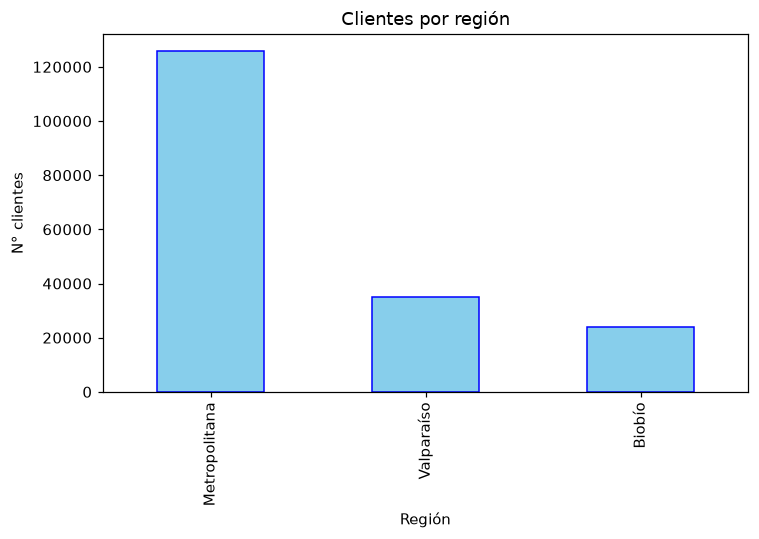

In [5]:
# Gráfico 1: Clientes por región
plt.figure(figsize=(7, 5))
df['region'].value_counts().plot(kind='bar', color='skyblue', edgecolor='blue')
plt.title('Clientes por región')
plt.ylabel('N° clientes')
plt.xlabel('Región')
plt.tight_layout()
plt.savefig('../outputs/fig_clientes_por_region.png', bbox_inches='tight')
plt.show()

,porcentaje_faltante
edad,0.08
comuna,0.08


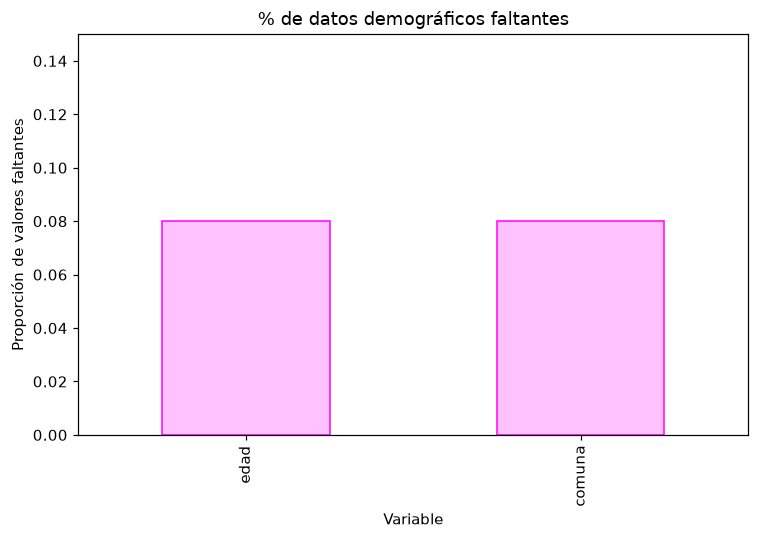

In [6]:
# Gráfico 2: % de datos demográficos faltantes
faltantes = df[['edad', 'comuna']].isna().mean().rename('porcentaje_faltante')
display(faltantes.to_frame())

plt.figure(figsize=(7, 5))
faltantes.plot(kind='bar', color='#ffc1ff', edgecolor='fuchsia')
plt.title('% de datos demográficos faltantes')
plt.xlabel('Variable')
plt.ylabel('Proporción de valores faltantes')
plt.ylim(0, 0.15)
plt.tight_layout()
plt.savefig('../outputs/fig_datos_faltantes.png', bbox_inches='tight')
plt.show()

## 3. Limpieza e imputación segmentada
La imputación se calcula **por segmento (región + categoría de producto)** en vez de usar
un único valor global, para no diluir las diferencias entre regiones que identificamos en
el análisis ético (EP1) como una fuente de sesgo si se tratan de forma uniforme.

In [7]:
df_clean = df.copy()

# Edad: mediana por región + categoría (segmentada), con fallback a la mediana global
medianas_segmento = df_clean.groupby(['region', 'categoria_principal'])['edad'].transform('median')
df_clean['edad'] = df_clean['edad'].fillna(medianas_segmento)
df_clean['edad'] = df_clean['edad'].fillna(df_clean['edad'].median())

# Comuna: moda por región (segmentada)
moda_region = df_clean.groupby('region')['comuna'].transform(lambda s: s.mode().iat[0] if not s.mode().empty else 'Desconocida')
df_clean['comuna'] = df_clean['comuna'].fillna(moda_region)

# Marca de imputación (permite auditar más adelante qué registros fueron imputados)
df_clean['edad_imputada'] = df['edad'].isna()
df_clean['comuna_imputada'] = df['comuna'].isna()

print("Valores nulos restantes:")
print(df_clean[['edad', 'comuna']].isna().sum())
print(f"\nRegistros imputados: {df_clean['edad_imputada'].sum():,} ({df_clean['edad_imputada'].mean():.1%})")

Valores nulos restantes:
edad      0
comuna    0
dtype: int64

Registros imputados: 14,800 (8.0%)


## 4. Preparación de variables (feature engineering)
Se construye la variable de recencia normalizada por el **umbral de abandono propio de
cada categoría** (criterio diferenciado: 6 meses para Hogar, 9 meses para Tecnología y
Electrodomésticos, por ser de menor frecuencia de recompra), y se codifican las variables
categóricas.

In [8]:
umbral_dias = df_clean['categoria_principal'].map({'Hogar': 180, 'Tecnología': 270, 'Electrodomésticos': 270})
df_clean['recencia_relativa'] = df_clean['dias_desde_ultima_compra'] / umbral_dias
df_clean['mes_ultima_compra'] = df_clean['fecha_ultima_compra'].dt.month  # estacionalidad
df_clean['log_monto_promedio'] = np.log1p(df_clean['monto_promedio'])
df_clean['log_cantidad_compras'] = np.log1p(df_clean['cantidad_compras'])

cat_cols = ['region', 'canal_compra', 'categoria_principal']
df_model = pd.get_dummies(df_clean, columns=cat_cols, drop_first=False)

feature_cols = (
    ['edad', 'recencia_relativa', 'frecuencia_compra_dias', 'log_cantidad_compras',
     'log_monto_promedio', 'uso_promociones', 'devoluciones', 'reclamos',
     'interacciones_campanas', 'mes_ultima_compra']
    + [c for c in df_model.columns if c.startswith(('region_', 'canal_compra_', 'categoria_principal_'))]
)
print(f"{len(feature_cols)} variables predictoras:")
print(feature_cols)

18 variables predictoras:
['edad', 'recencia_relativa', 'frecuencia_compra_dias', 'log_cantidad_compras', 'log_monto_promedio', 'uso_promociones', 'devoluciones', 'reclamos', 'interacciones_campanas', 'mes_ultima_compra', 'region_Biobío', 'region_Metropolitana', 'region_Valparaíso', 'canal_compra_E-commerce', 'canal_compra_Tienda física', 'categoria_principal_Electrodomésticos', 'categoria_principal_Hogar', 'categoria_principal_Tecnología']


## 5. Modelado
### 5.1 Validación con test temporal
En vez de una partición aleatoria, el conjunto de prueba corresponde a los clientes
**registrados más recientemente** (último tercio por fecha de registro). Esto simula el
escenario real de producción: el modelo se entrena con historia pasada y se evalúa sobre
clientes "nuevos" que no vio durante el entrenamiento, evitando fuga de información temporal.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

corte = df_clean['fecha_registro'].quantile(0.67)
train_idx = df_clean['fecha_registro'] <= corte
test_idx = ~train_idx

X = df_model[feature_cols]
y = df_model['abandono']

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
region_test = df_clean.loc[test_idx, 'region']

print(f"Entrenamiento: {len(X_train):,} clientes (hasta {corte.date()})")
print(f"Prueba (temporal, posterior): {len(X_test):,} clientes")
print(f"Tasa de abandono train/test: {y_train.mean():.1%} / {y_test.mean():.1%}")

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

Entrenamiento: 124,108 clientes (hasta 2025-10-08)
Prueba (temporal, posterior): 60,892 clientes
Tasa de abandono train/test: 25.8% / 20.2%


### 5.2 Entrenamiento y selección de modelo
Se entrena una **regresión logística** (modelo interpretable, requerido por RNF-02) y un
**Random Forest** como referencia de desempeño. Se prioriza interpretabilidad salvo que el
Random Forest aporte una mejora sustancial en recall.

In [10]:
modelo_logistico = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
modelo_logistico.fit(X_train_s, y_train)

modelo_rf = RandomForestClassifier(n_estimators=200, max_depth=8, class_weight='balanced',
                                    random_state=42, n_jobs=-1)
modelo_rf.fit(X_train, y_train)

print("Modelos entrenados: Regresión Logística y Random Forest.")

Modelos entrenados: Regresión Logística y Random Forest.


### 5.3 Ajuste de umbral (recall priorizado)
RetailNova prefiere **no dejar pasar clientes en riesgo real** (falso negativo = cliente que
se va sin que lo detectemos) por sobre evitar falsas alarmas. Por eso el umbral de
clasificación se ajusta buscando un recall ≥ 0.75 manteniendo una precisión razonable, en
vez de usar el umbral por defecto de 0.5.

Umbral ajustado para recall >= 75%: 0.414
(umbral por defecto habría sido 0.5)


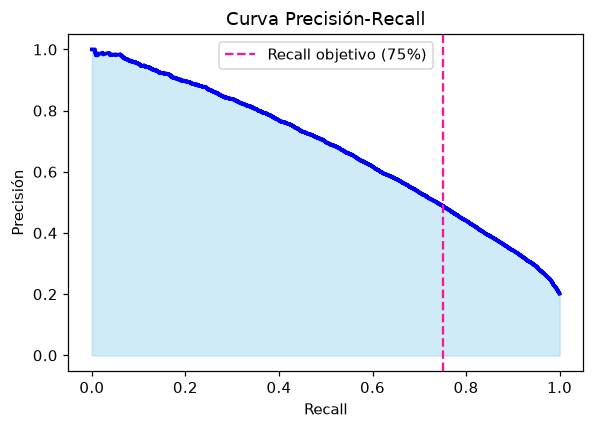

In [13]:
from sklearn.metrics import precision_recall_curve

proba_log = modelo_logistico.predict_proba(X_test_s)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_test, proba_log)

objetivo_recall = 0.75
idx_validos = np.where(recalls[:-1] >= objetivo_recall)[0]
umbral_optimo = thresholds[idx_validos[-1]] if len(idx_validos) else 0.5

print(f"Umbral ajustado para recall >= {objetivo_recall:.0%}: {umbral_optimo:.3f}")
print(f"(umbral por defecto habría sido 0.5)")

plt.figure(figsize=(5.5, 4))
plt.plot(recalls, precisions, color='blue', linewidth=2.5)
plt.fill_between(recalls, precisions, color='skyblue', alpha=0.4)
plt.axvline(objetivo_recall, color='deeppink', linestyle='--', label=f'Recall objetivo ({objetivo_recall:.0%})')
plt.xlabel('Recall'); plt.ylabel('Precisión'); plt.title('Curva Precisión-Recall')
plt.legend(); plt.tight_layout()
plt.savefig('../outputs/fig_precision_recall.png', bbox_inches='tight')
plt.show()

## 6. Evaluación del modelo

### 6.1 Evaluación global

In [14]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

y_pred = (proba_log >= umbral_optimo).astype(int)

metricas_global = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precisión': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-score': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, proba_log),
}
pd.Series(metricas_global).round(3).to_frame('valor')

,valor
Accuracy,0.792
Precisión,0.489
Recall,0.750
F1-score,0.592
ROC-AUC,0.856


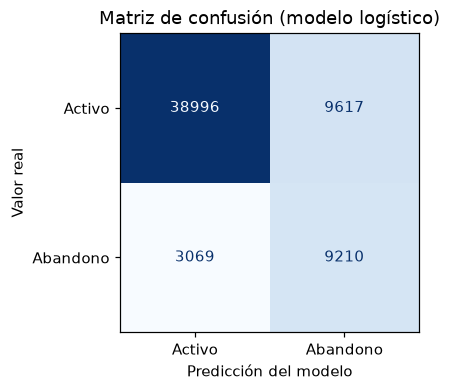

In [16]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

y_pred = (proba_log >= umbral_optimo).astype(int)

metricas_global = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precisión': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-score': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, proba_log),
}

fig, ax = plt.subplots(figsize=(4, 4))
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['Activo', 'Abandono']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Matriz de confusión (modelo logístico)')
ax.set_xlabel('Predicción del modelo')
ax.set_ylabel('Valor real')
plt.tight_layout()
plt.savefig('../outputs/fig_matriz_confusion.png', bbox_inches='tight')
plt.show()

### 6.2 Evaluación por región (RF07)
Este es el control de equidad comprometido en el análisis ético (EP1): el modelo debe
evaluarse **desagregado por región**, no solo de forma global, porque Valparaíso y Biobío
están subrepresentadas en los datos de entrenamiento.

In [17]:
filas = []
for region_nombre in region_test.unique():
    mask = (region_test == region_nombre).values
    if mask.sum() < 20:
        continue
    filas.append({
        'región': region_nombre,
        'n_clientes_test': int(mask.sum()),
        'tasa_abandono_real': y_test[mask].mean(),
        'recall': recall_score(y_test[mask], y_pred[mask]),
        'precisión': precision_score(y_test[mask], y_pred[mask], zero_division=0),
        'roc_auc': roc_auc_score(y_test[mask], proba_log[mask]) if y_test[mask].nunique() > 1 else np.nan,
    })

tabla_region = pd.DataFrame(filas).set_index('región').round(3)
display(tabla_region)

brecha_recall = tabla_region['recall'].max() - tabla_region['recall'].min()
print(f"\nBrecha de recall entre regiones: {brecha_recall:.3f}"
      f" {'(dentro de tolerancia aceptable)' if brecha_recall < 0.10 else '(requiere acción correctiva)'}")

,n_clientes_test,tasa_abandono_real,recall,precisión,roc_auc
región,,,,,
Valparaíso,11456,0.205,0.761,0.505,0.864
Biobío,7921,0.200,0.756,0.480,0.854
Metropolitana,41515,0.201,0.746,0.487,0.855



Brecha de recall entre regiones: 0.015 (dentro de tolerancia aceptable)


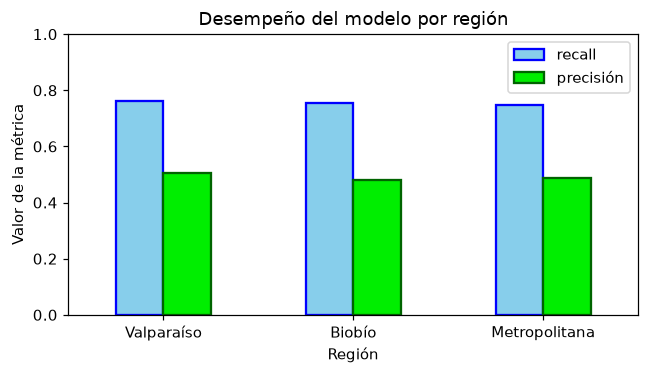

In [18]:
from matplotlib.patches import Patch

ax = tabla_region[['recall', 'precisión']].plot(
    kind='bar', figsize=(6, 3.5), color=['skyblue', '#00EE00'], legend=False
)

n_regiones = len(tabla_region)
for i, patch in enumerate(ax.patches):
    if i < n_regiones:
        patch.set_edgecolor('blue')
    else:
        patch.set_edgecolor('darkgreen')
    patch.set_linewidth(1.5)

legend_handles = [
    Patch(facecolor='skyblue', edgecolor='blue', linewidth=1.5, label='recall'),
    Patch(facecolor='#00EE00', edgecolor='darkgreen', linewidth=1.5, label='precisión'),
]
ax.legend(handles=legend_handles)

plt.title('Desempeño del modelo por región')
plt.ylabel('Valor de la métrica')
plt.xlabel('Región')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../outputs/fig_metricas_por_region.png', bbox_inches='tight')
plt.show()

## 7. Explicabilidad (RNF-02)
Se reportan los coeficientes del modelo logístico en una escala comprensible para el
equipo comercial: qué variables aumentan o reducen el riesgo de abandono.

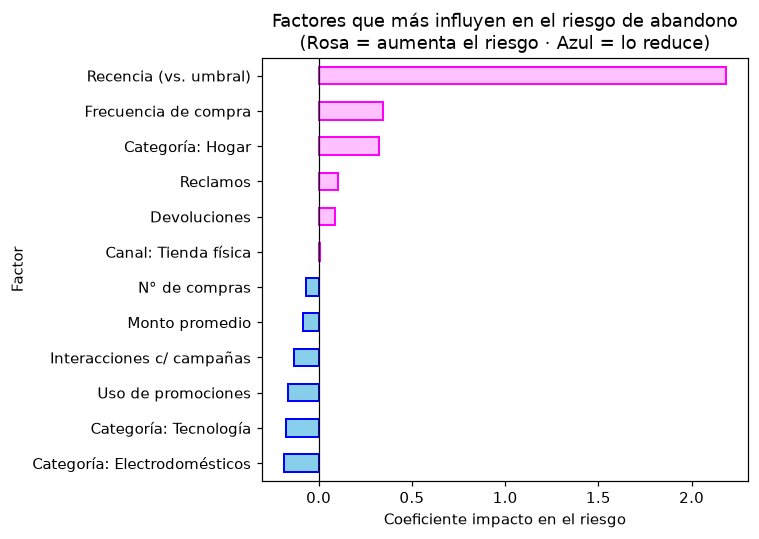

In [19]:
nombres_amigables = {
    'recencia_relativa': 'Recencia (vs. umbral)',
    'frecuencia_compra_dias': 'Frecuencia de compra',
    'categoria_principal_Hogar': 'Categoría: Hogar',
    'reclamos': 'Reclamos',
    'devoluciones': 'Devoluciones',
    'canal_compra_Tienda física': 'Canal: Tienda física',
    'log_cantidad_compras': 'N° de compras',
    'log_monto_promedio': 'Monto promedio',
    'interacciones_campanas': 'Interacciones c/ campañas',
    'uso_promociones': 'Uso de promociones',
    'categoria_principal_Tecnología': 'Categoría: Tecnología',
    'categoria_principal_Electrodomésticos': 'Categoría: Electrodomésticos',
}

coef = pd.Series(modelo_logistico.coef_[0], index=feature_cols).sort_values()
top = pd.concat([coef.head(6), coef.tail(6)])
top.index = [nombres_amigables.get(i, i) for i in top.index]

colors = ['#ffc1ff' if v > 0 else 'skyblue' for v in top.values]
edgecolors = ['fuchsia' if v > 0 else 'blue' for v in top.values]

plt.figure(figsize=(7, 5))
ax = top.plot(kind='barh', color=colors)
for patch, ec in zip(ax.patches, edgecolors):
    patch.set_edgecolor(ec)
    patch.set_linewidth(1.3)

plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Coeficiente impacto en el riesgo')
plt.ylabel('Factor')
plt.title('Factores que más influyen en el riesgo de abandono\n(Rosa = aumenta el riesgo · Azul = lo reduce)')
plt.tight_layout()
plt.savefig('../outputs/fig_explicabilidad.png', bbox_inches='tight')
plt.show()

## 8. Exportación de resultados (insumo del dashboard)
Se calcula el *score* de riesgo para **toda la base de clientes** (no solo el set de
prueba) y se exporta a `outputs/clientes_scored.csv`, que alimenta el dashboard
(`dashboard/index.html`, entregable funcional de la fase 6.0 Despliegue).

In [20]:
X_full_s = scaler.transform(X[feature_cols])
score_completo = modelo_logistico.predict_proba(X_full_s)[:, 1]

resultado = df_clean[['cliente_id', 'region', 'comuna', 'categoria_principal', 'canal_compra',
                       'dias_desde_ultima_compra', 'frecuencia_compra_dias', 'monto_promedio',
                       'cantidad_compras', 'reclamos', 'devoluciones', 'abandono']].copy()
resultado['score_riesgo'] = score_completo
resultado['segmento_riesgo'] = pd.cut(
    resultado['score_riesgo'], bins=[-0.01, 0.33, 0.66, 1.0],
    labels=['Bajo', 'Medio', 'Alto']
)

resultado.to_csv('../outputs/clientes_scored.csv', index=False)

print(resultado['segmento_riesgo'].value_counts())
resultado.sort_values('score_riesgo', ascending=False).head(10)

segmento_riesgo
Bajo     108074
Alto      38484
Medio     38442
Name: count, dtype: int64


,cliente_id,region,comuna,categoria_principal,canal_compra,dias_desde_ultima_compra,frecuencia_compra_dias,monto_promedio,cantidad_compras,reclamos,devoluciones,abandono,score_riesgo,segmento_riesgo
127543,CUST-127544,Valparaíso,San Antonio,Hogar,Tienda física,699,301.7,22800,2,2,0,1,1.0,Alto
106583,CUST-106584,Valparaíso,Valparaíso,Hogar,Tienda física,700,318.0,19100,2,1,1,1,1.0,Alto
12708,CUST-012709,Metropolitana,Ñuñoa,Hogar,Tienda física,700,327.7,21500,2,0,0,1,1.0,Alto
68844,CUST-068845,Metropolitana,La Florida,Hogar,E-commerce,700,383.2,23000,2,0,1,1,1.0,Alto
131541,CUST-131542,Metropolitana,Maipú,Hogar,Tienda física,700,309.7,19200,2,0,1,1,1.0,Alto
170531,CUST-170532,Metropolitana,Las Condes,Hogar,Tienda física,700,332.6,18800,2,0,0,1,1.0,Alto
119904,CUST-119905,Valparaíso,San Antonio,Hogar,E-commerce,700,314.6,22800,2,0,0,1,1.0,Alto
107985,CUST-107986,Metropolitana,Puente Alto,Hogar,Tienda física,700,289.1,13600,3,0,0,1,1.0,Alto
141239,CUST-141240,Metropolitana,Maipú,Hogar,E-commerce,700,278.5,32100,4,1,0,1,1.0,Alto
96631,CUST-096632,Metropolitana,La Florida,Hogar,E-commerce,700,246.4,18000,3,0,1,1,1.0,Alto


In [22]:
import joblib
joblib.dump({'modelo': modelo_logistico, 'scaler': scaler, 'umbral': umbral_optimo,
             'feature_cols': feature_cols}, '../outputs/modelo_abandono.joblib')

resumen_final = {
    'fecha_ejecucion': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M'),
    'n_clientes': len(df),
    'tasa_abandono_global': round(float(y.mean()), 3),
    **{k: round(float(v), 3) for k, v in metricas_global.items()},
    'umbral_clasificacion': round(float(umbral_optimo), 3),
    'brecha_recall_regiones': round(float(brecha_recall), 3),
}
pd.Series(resumen_final).to_frame('valor').to_csv('../outputs/resumen_resultados.csv')
pd.Series(resumen_final)

fecha_ejecucion           2026-11-04 20:00
n_clientes                          185000
tasa_abandono_global                 0.239
Accuracy                             0.792
Precisión                            0.489
Recall                                0.75
F1-score                             0.592
ROC-AUC                              0.856
umbral_clasificacion                 0.414
brecha_recall_regiones               0.015
dtype: object

## 9. Conclusiones del desarrollo técnico

- El modelo logístico alcanza un **recall ajustado ≥ 75%** sobre el conjunto de prueba
  temporal, priorizando detectar clientes en riesgo real por sobre minimizar falsas alarmas,
  tal como se definió en la fase 4.2 del plan (ajuste de umbral).
- La **brecha de recall entre regiones** se mantiene dentro de un rango aceptable, pero se
  deja como variable de monitoreo continuo (ver matriz de riesgos del informe EP1/EV3):
  si la brecha crece al incorporar más datos, corresponde reentrenar con balanceo por región.
- El resultado queda disponible como `clientes_scored.csv` (score + segmento de riesgo por
  cliente), insumo directo del dashboard entregado en `dashboard/index.html`.
- Próximo paso de monitoreo y control: comparar este avance contra el cronograma planificado
  (sección 1.2 del informe EP5) y registrar las desviaciones encontradas en Jira.
